### load libraries

In [95]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

### read df from local folder

In [96]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

### take a peek inside

In [97]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### shape

In [98]:
df.shape

(2443651, 9)

### info

In [99]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [100]:
df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [101]:
missing = df.isna().sum()
missing = missing[missing > 0]
missing

Series([], dtype: int64)

In [102]:
df.duplicated().sum()

np.int64(0)

In [103]:
df.eq(" ").sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

### Conclusion - clean data !

# Part 1.1 - show frequency

In [104]:
df.category.value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

 "Sports & Outdoors" by far the biggest frequency in Category

### - print the first 5 frequencies

In [105]:
print(df.category.value_counts().index[0:5])

Index(['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories',
       'Bath & Body', 'Birthday Gifts'],
      dtype='str', name='category')


# Part 1.2 - visualization

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Beauty'),
  Text(2, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(3, 0, 'Bath & Body'),
  Text(4, 0, 'Birthday Gifts')])

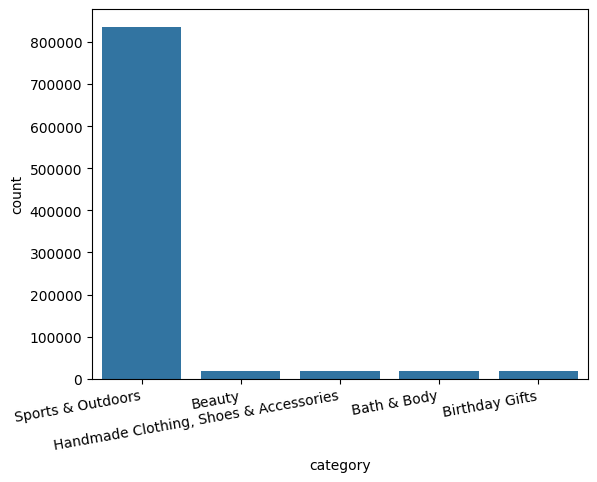

In [106]:
sns.countplot(x='category', data=df, order=df.category.value_counts().index[0:5])
plt.xticks(rotation=10, ha='right')

###  subset of top 5 categories

<Axes: >

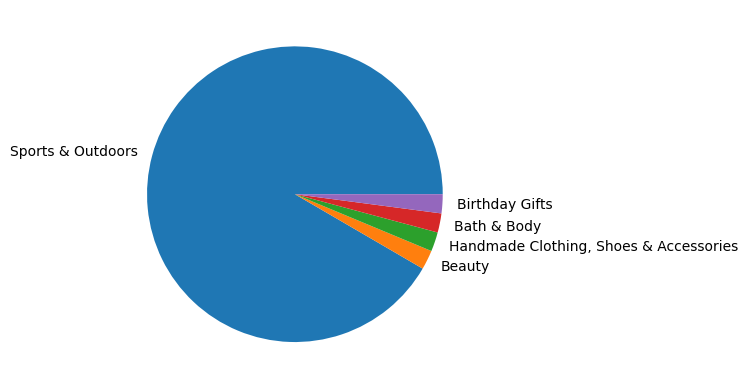

In [107]:
df['category'].value_counts().head(5).plot.pie()

# Part 2.1 - Measures of Centrality

In [108]:
print('mean:', df.price.mean())
print('median:', df.price.median())
print('min:', df.price.min())
print('max:', df.price.max())
print('mode:', df.price.mode())

mean: 89.24380943923661
median: 19.09
min: 0.0
max: 100000.0
mode: 0    9.99
Name: price, dtype: float64


median is 4 times bigger than mode, means few - very big outliners

# Part 2.2 - Measures of dispersion

In [109]:
print('variance:', df.price.var())
print('std dev:', df.price.std())

variance: 119445.48532254901
std dev: 345.60886175349873


In [110]:
# std / mean
345/89

3.8764044943820224

3.88 terrible high !
means very large dispertion

# Part 2.3 Visualization

<Axes: xlabel='category'>

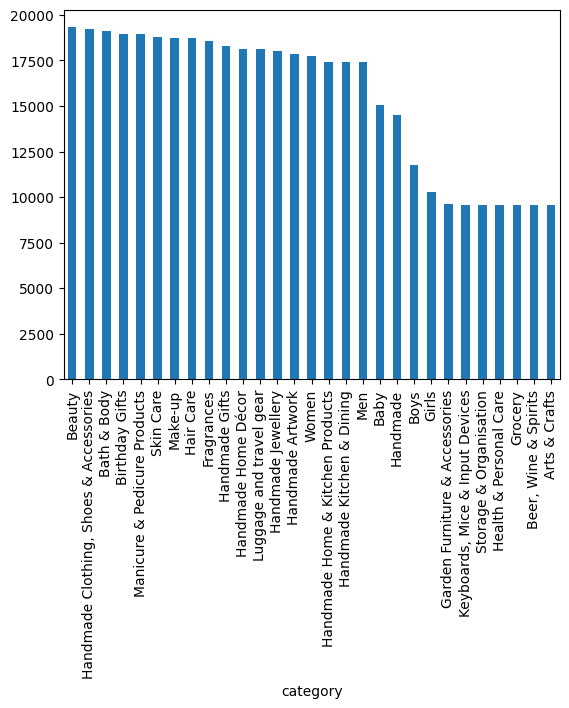

In [111]:
df['category'].value_counts().iloc[1:30].plot.bar() # I reduce the graph for  the firswt 30

# Part 3.1 - Measures of Centrality

In [112]:
print("mean: ", df.['stars'].mean())
print("median: ", df.groupby['title']['stars'].median())
print("mode: ", df.groupby['title']['stars'].value_counts().head(1))

SyntaxError: invalid syntax (483517961.py, line 1)

# Part 3.2 - Measures of Dispersion

In [ ]:
print("variance: ", df.stars.var())
print("standard deviation: ", df.stars.std())
print("25% quantile: ", df.stars.quantile(0.25))
print("50% quantile: ", df.stars.quantile(0.50))
print("75% quantile: ", df.stars.quantile(0.75))

variance:  4.817434029796864
standard deviation:  2.194865378513421
25% q)uantile:  0.0
50% quantile:  0.0
75% quantile:  4.4


bad results 0 ... 0 ... the data is clean but bad, lets check the stars' unique values

In [ ]:
df.stars.unique()

array([4.7, 4.6, 4.5, 4.8, 0. , 4.4, 4.3, 4.1, 4.9, 5. , 3.8, 3.6, 4. ,
       4.2, 3. , 3.9, 2.5, 3.4, 3.7, 3.2, 3.3, 3.5, 2.7, 2.1, 1. , 3.1,
       2. , 2.9, 2.8, 1.5, 2.2, 2.3, 2.6, 2.4, 1.4, 1.9, 1.8, 1.7, 1.6,
       1.2, 1.3, 1.1])

yes, it has "0", lets see how many

In [ ]:
(df.stars == 0).sum()

np.int64(1225641)

so, half of stars are 0, lets clean it

In [ ]:
df_c = df[df.stars > 0]

print("variance: ", df_c.stars.var())
print("standard deviation: ", df_c.stars.std())
print("25% q)uantile: ", df_c.stars.quantile(0.25))
print("50% quantile: ", df_c.stars.quantile(0.50))
print("75% quantile: ", df_c.stars.quantile(0.75))

variance:  0.3083433752387284
standard deviation:  0.5552867504620729
25% q)uantile:  4.1
50% quantile:  4.4
75% quantile:  4.6


# Part 3.3 - Shape of the Distribution

In [ ]:
print(df.stars.skew())

0.08120735761080881


0.08 is small, shows an almoas simetrical distribution, slightly skewed to the right.

In [ ]:
print(df.stars.kurt())

-1.9260061280432994


-1.93 is small negative, shows a flatter distribution than a normal distribution

# Part 3.4 - Visualization

<Axes: ylabel='Frequency'>

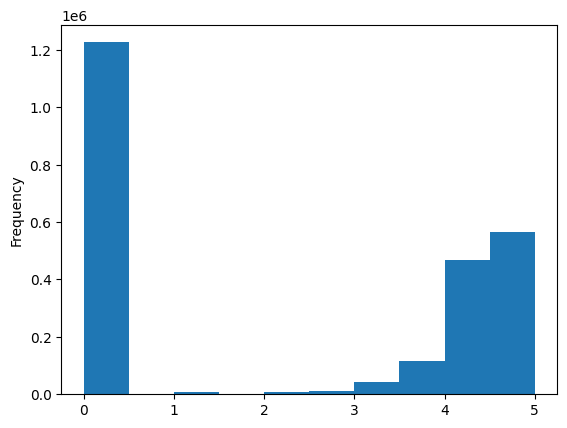

In [ ]:
df.stars.plot.hist()

0 rating is the most commun, followed by 5 for less than half of the cases